# Fuzzy and Crisp State Representation

How `agent-dipa` turns four continuous metrics into a Q-table key, and what the
fuzzy and crisp agents do differently with the same partition.

Three agents share one training loop, one reward and one action space, and
differ only in the map from observation to state key:

| Agent | State key | States per observation |
|---|---|---|
| `Q-LEARNING` | the raw continuous metrics | 1, almost never revisited |
| `Q-LEARNING-CRISP` | one hard band per metric | exactly 1 |
| `Q-LEARNING-FUZZY` | every band each metric belongs to | 1 to 2^4 = 16, weighted |

Every number and curve below is read out of `agent-dipa/rl/fuzzy.py` and
`agent-dipa/rl/crisp.py` at run time rather than copied into this notebook, so
the figures cannot drift from the agents that were actually trained. The
empirical sections read the 60-episode training run in `data/training/`.

In [ ]:
import importlib
import sys
import types
from itertools import product
from math import comb
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

%matplotlib inline

# --- Load the agent's own fuzzy/crisp definitions --------------------------
# rl/__init__.py imports the whole agent stack (Kubernetes client, urllib3),
# none of which this notebook needs, so `rl` is registered by hand as a package
# pointing at agent-dipa/rl. Only fuzzy.py and crisp.py are then imported.
REPO_ROOT = Path.cwd().parent
AGENT_RL = REPO_ROOT / 'agent-dipa' / 'rl'
if not AGENT_RL.is_dir():
    raise FileNotFoundError(f'Expected the agent package at {AGENT_RL}')

if 'rl' not in sys.modules:
    _pkg = types.ModuleType('rl')
    _pkg.__path__ = [str(AGENT_RL)]
    sys.modules['rl'] = _pkg

importlib.import_module('rl.fuzzy')
importlib.import_module('rl.crisp')

from rl.crisp import Crisp  # noqa: E402
from rl.fuzzy import (  # noqa: E402
    CRISP_BOUNDARIES,
    LABELS,
    METRICS,
    TRAPEZOIDS,
    Fuzzy,
    normalize_observation,
)

# MAX_REPLICAS of the 60-episode run (data/model/60-episodes/.env). The agents
# take it as n_actions, and Fuzzy uses it to put a replica count on the 0-100
# scale, so last_replica's bands move with it.
MAX_REPLICAS = 10

LOW_CUT, HIGH_CUT = CRISP_BOUNDARIES
fuzzy = Fuzzy(max_replicas=MAX_REPLICAS)
crisp = Crisp(max_replicas=MAX_REPLICAS)


def membership_curve(label, xs):
    """Membership degree of `label` over `xs`, through the agent's own functions."""
    fn = fuzzy.memberships[METRICS[0]][label]  # all four metrics share one partition
    return np.array([fn(float(x)) for x in xs])


def state_label(key):
    """('low', 'medium', ...) -> 'L-M-...' for axis ticks."""
    return '-'.join(part[0].upper() for part in key)


geometry = pd.DataFrame(
    [
        {
            'band': label,
            'a': a, 'b': b, 'c': c, 'd': d,
            'core (degree = 1)': f'[{b:g}, {c:g}]',
            'support (degree > 0)': f'[{a:g}, {d:g}]',
        }
        for label, (a, b, c, d) in TRAPEZOIDS.items()
    ]
).set_index('band')

print(f'Loaded  : {AGENT_RL}')
print(f'Metrics : {", ".join(METRICS)}  (all share one partition)')
print(f'Labels  : {", ".join(LABELS)}')
print(f'Crisp   : low < {LOW_CUT:g} <= medium < {HIGH_CUT:g} <= high')
print(f'Replicas: 1..{MAX_REPLICAS} rescaled onto 0-100%')
geometry

Loaded  : C:\Users\indra\Documents\Projects\autoscaling-k8s-reinforcement-learning\agent-dipa\rl
Metrics : cpu_usage, memory_usage, response_time, last_replica  (all share one partition)
Labels  : low, medium, high
Crisp   : low < 32.5 <= medium < 67.5 <= high
Replicas: 1..10 rescaled onto 0-100%


,a,b,c,d,core (degree = 1),support (degree > 0)
band,,,,,,
low,0.0,0.0,25.0,40.0,"[0, 25]","[0, 40]"
medium,25.0,40.0,60.0,75.0,"[40, 60]","[25, 75]"
high,60.0,75.0,100.0,100.0,"[75, 100]","[60, 100]"


In [ ]:
# --- Figure theme ----------------------------------------------------------
# One meaning per colour channel, per figure:
#   * a figure about the three bands colours by band, using an ordinal ramp
#     (light -> dark = low -> high) because the bands are ordered, and carries
#     the fuzzy/crisp distinction in line style instead;
#   * a figure comparing the two representations as entities gives each its own
#     categorical hue.
# Both palettes were checked for colour-vision-deficiency separation rather
# than picked by eye; the traffic-light green/amber/red of the earlier notebook
# was not (its amber and green collapse onto each other under protanopia).
SURFACE = '#fcfcfb'
INK = '#0b0b0b'
INK_2 = '#52514e'
INK_MUTED = '#8a8984'
GRID = '#e6e5e1'

BAND_COLORS = {'low': '#86b6ef', 'medium': '#2a78d6', 'high': '#104281'}
REPR_COLORS = {'Fuzzy': '#2a78d6', 'Crisp': '#eb6834'}
BAND_TITLE = {'low': 'Low', 'medium': 'Medium', 'high': 'High'}
METRIC_TITLE = {
    'cpu_usage': 'CPU usage',
    'memory_usage': 'Memory usage',
    'response_time': 'Response time',
    'last_replica': 'Last replica',
}

mpl.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 200,
    'figure.facecolor': SURFACE,
    'savefig.facecolor': SURFACE,
    'axes.facecolor': SURFACE,
    'axes.edgecolor': GRID,
    'axes.linewidth': 0.8,
    'axes.grid': True,
    'axes.axisbelow': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelcolor': INK_2,
    'axes.titlecolor': INK,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.titlelocation': 'left',
    'axes.titlepad': 10,
    'axes.labelsize': 10,
    'grid.color': GRID,
    'grid.linestyle': '-',
    'grid.linewidth': 0.8,
    'xtick.color': INK_MUTED,
    'ytick.color': INK_MUTED,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'text.color': INK,
    'legend.frameon': False,
    'legend.fontsize': 9,
    'font.size': 10,
    'lines.solid_capstyle': 'round',
})


def band_legend(ax, **kwargs):
    """Legend for the three bands, in band order rather than plot order."""
    handles = [Patch(facecolor=BAND_COLORS[b], label=BAND_TITLE[b]) for b in LABELS]
    return ax.legend(handles=handles, **kwargs)


def annotate_cuts(ax, label_y=None):
    """Mark the crisp cut-offs, which are also the fuzzy crossover points."""
    for cut in (LOW_CUT, HIGH_CUT):
        ax.axvline(cut, color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1, zorder=1)
        if label_y is not None:
            ax.annotate(f'{cut:g}', xy=(cut, label_y), xycoords=('data', 'axes fraction'),
                        ha='center', va='bottom', fontsize=8, color=INK_MUTED)


# The zones where two bands are active at once: [a of the upper set, d of the
# lower set]. Everything fuzzy and crisp disagree about happens inside them.
OVERLAPS = [
    (TRAPEZOIDS[upper][0], TRAPEZOIDS[lower][3])
    for lower, upper in (('low', 'medium'), ('medium', 'high'))
]
OVERLAP_WIDTH = sum(hi - lo for lo, hi in OVERLAPS)

# Every edge of the partition, so an axis over the 0-100 scale is ticked where
# something actually happens rather than every 20%.
PARTITION_TICKS = sorted({0.0, 100.0, LOW_CUT, HIGH_CUT}
                         | {edge for lo, hi in OVERLAPS for edge in (lo, hi)})


def partition_xaxis(ax, label='Normalized metric value (%)'):
    ax.set_xlim(0, 100)
    ax.set_xticks(PARTITION_TICKS)
    ax.set_xticklabels([f'{v:g}' for v in PARTITION_TICKS])
    if label:
        ax.set_xlabel(label)

print('Overlap zones (two bands active): '
      + ', '.join(f'{lo:g}-{hi:g}%' for lo, hi in OVERLAPS)
      + f'  ->  {OVERLAP_WIDTH:g}% of the 0-100 range')

Overlap zones (two bands active): 25-40%, 60-75%  ->  30% of the 0-100 range


## 1. The partition every metric shares

One set of trapezoids serves all four metrics, so a single panel describes the
whole state representation. The three sets form a **Ruspini partition**: each
falling edge coincides exactly with the next set's rising edge, so the degrees
sum to 1 everywhere and each pair of neighbours crosses at degree 0.5. Those
crossings are where `argmax` changes hands, which is why `crisp.py` derives its
cut-offs from them instead of hand-picking thresholds.

findfont: Failed to find font weight semibold, now using 700.


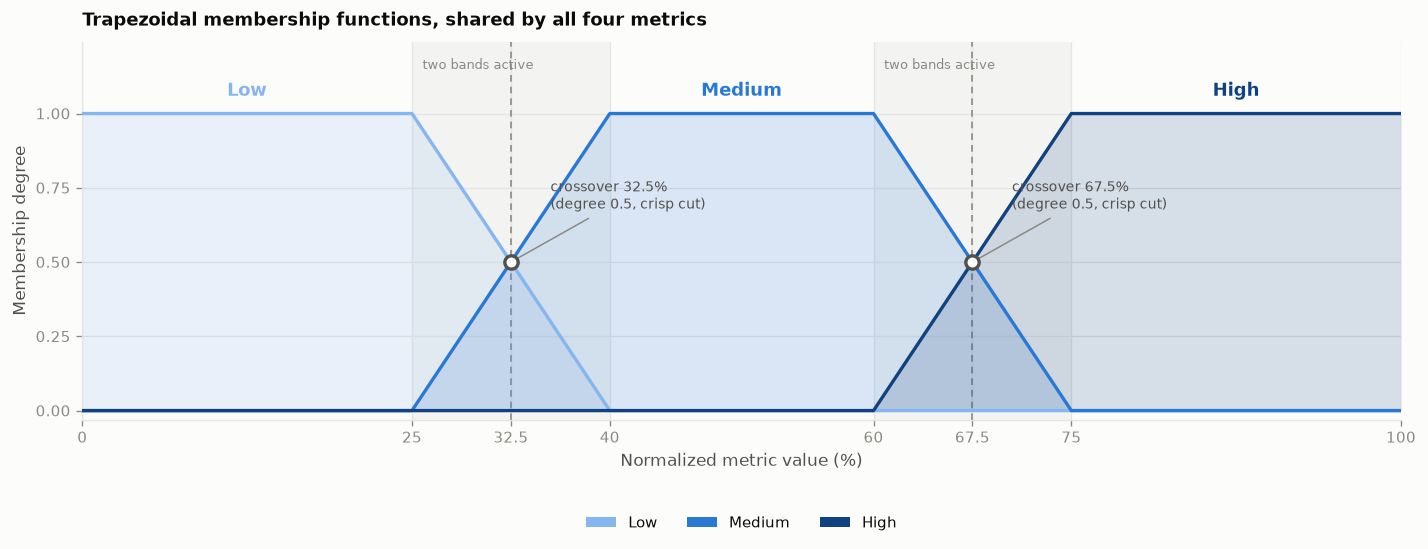

,a,b,c,d,core (degree = 1),support (degree > 0)
band,,,,,,
low,0.0,0.0,25.0,40.0,"[0, 25]","[0, 40]"
medium,25.0,40.0,60.0,75.0,"[40, 60]","[25, 75]"
high,60.0,75.0,100.0,100.0,"[75, 100]","[60, 100]"


In [ ]:
x = np.linspace(0, 100, 2001)
degrees = {label: membership_curve(label, x) for label in LABELS}

fig, ax = plt.subplots(figsize=(12, 4.8))

for lo, hi in OVERLAPS:
    ax.axvspan(lo, hi, color=INK_MUTED, alpha=0.07, linewidth=0, zorder=0)

for label in LABELS:
    y = degrees[label]
    ax.fill_between(x, y, color=BAND_COLORS[label], alpha=0.16, linewidth=0, zorder=2)
    ax.plot(x, y, color=BAND_COLORS[label], linewidth=2, zorder=3)

# Direct labels on the plateaus, where each band is the only one active.
for label, (_, b, c, _) in TRAPEZOIDS.items():
    ax.annotate(BAND_TITLE[label], xy=((b + c) / 2, 1.045), ha='center', va='bottom',
                color=BAND_COLORS[label], fontsize=11, fontweight='semibold')

annotate_cuts(ax)
for cut in (LOW_CUT, HIGH_CUT):
    ax.plot([cut], [0.5], marker='o', markersize=8, markerfacecolor=SURFACE,
            markeredgecolor=INK_2, markeredgewidth=2, zorder=4)
    ax.annotate(f'crossover {cut:g}%\n(degree 0.5, crisp cut)', xy=(cut, 0.5),
                xytext=(cut + 3, 0.68), fontsize=8.5, color=INK_2,
                arrowprops=dict(arrowstyle='-', color=INK_MUTED, linewidth=0.9))

for lo, hi in OVERLAPS:
    # Left-aligned inside the span rather than centred, to clear the cut line.
    ax.annotate('two bands active', xy=(lo + 0.8, 1.15), ha='left',
                fontsize=8, color=INK_MUTED)

partition_xaxis(ax)
ax.set_ylim(-0.03, 1.24)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_ylabel('Membership degree')
ax.set_title('Trapezoidal membership functions, shared by all four metrics')
band_legend(ax, loc='upper center', bbox_to_anchor=(0.5, -0.22), ncols=3)

plt.tight_layout()
plt.show()

geometry[['a', 'b', 'c', 'd', 'core (degree = 1)', 'support (degree > 0)']]

## 2. The degrees always sum to 1

Stacking the three curves fills the panel exactly, with no gap and no overlap:
every value spends its whole membership somewhere. This is what makes the
weight normalization in `Fuzzy.get_activations` a no-op rather than a
correction, and what lets the crisp cut-offs be *derived* — on a Ruspini
partition the midpoint of an overlap is also the crossover point.

findfont: Failed to find font weight semibold, now using 700.


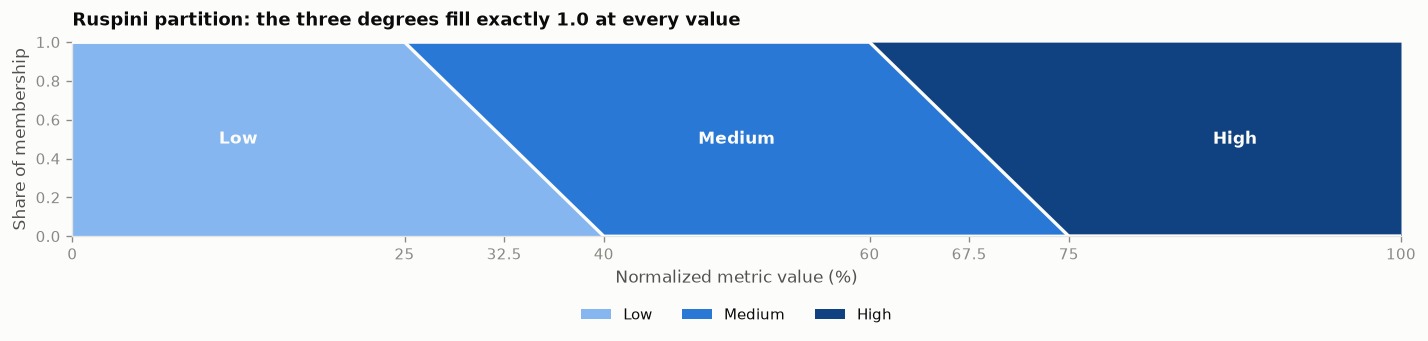

max |sum of degrees - 1| over 2001 sampled values: 0.00e+00


max |sum of raw firing strengths - 1| over 2000 random observations: 2.22e-16


In [ ]:
fig, ax = plt.subplots(figsize=(12, 3.2))

lower = np.zeros_like(x)
for label in LABELS:
    upper = lower + degrees[label]
    ax.fill_between(x, lower, upper, color=BAND_COLORS[label], linewidth=0, zorder=2)
    if label != LABELS[-1]:
        # A 2px surface gap separates the stacked fills instead of a border.
        ax.plot(x, upper, color=SURFACE, linewidth=2, zorder=3)
    lower = upper

for label, (_, b, c, _) in TRAPEZOIDS.items():
    ax.annotate(BAND_TITLE[label], xy=((b + c) / 2, 0.5), ha='center', va='center',
                color=SURFACE, fontsize=10, fontweight='semibold', zorder=4)

# No cut markers here: the seam between the fills crosses 0.5 exactly at the
# crossover, so drawing the cuts on top would only hide it.
partition_xaxis(ax)
ax.set_ylim(0, 1)
ax.set_ylabel('Share of membership')
ax.set_title('Ruspini partition: the three degrees fill exactly 1.0 at every value')
ax.grid(False)
band_legend(ax, loc='upper center', bbox_to_anchor=(0.5, -0.3), ncols=3)

plt.tight_layout()
plt.show()

total = sum(degrees.values())
print(f'max |sum of degrees - 1| over {len(x)} sampled values: {np.abs(total - 1).max():.2e}')

# The same property on the joint state: the product t-norm over four metrics
# already sums to 1 before get_activations normalizes it.
rng = np.random.default_rng(0)
worst = 0.0
for row in rng.uniform(0, 100, size=(2000, 4)):
    obs = dict(zip(METRICS, row))
    obs['last_replica'] = 1 + row[3] / 100 * (MAX_REPLICAS - 1)
    per_metric = fuzzy.fuzzify(obs)
    raw = sum(
        float(np.prod([per_metric[m][lab] for m, lab in zip(METRICS, combo)]))
        for combo in product(LABELS, repeat=4)
    )
    worst = max(worst, abs(raw - 1))
print(f'max |sum of raw firing strengths - 1| over 2000 random observations: {worst:.2e}')

## 3. The same cuts, hardened

`crisp.py` keeps the fuzzy study's discretization — the same three bands, cut at
the same two places — and drops the grading. The lower panel is the upper panel
with every value rounded to its strongest band, which turns the two crossings
into step discontinuities.

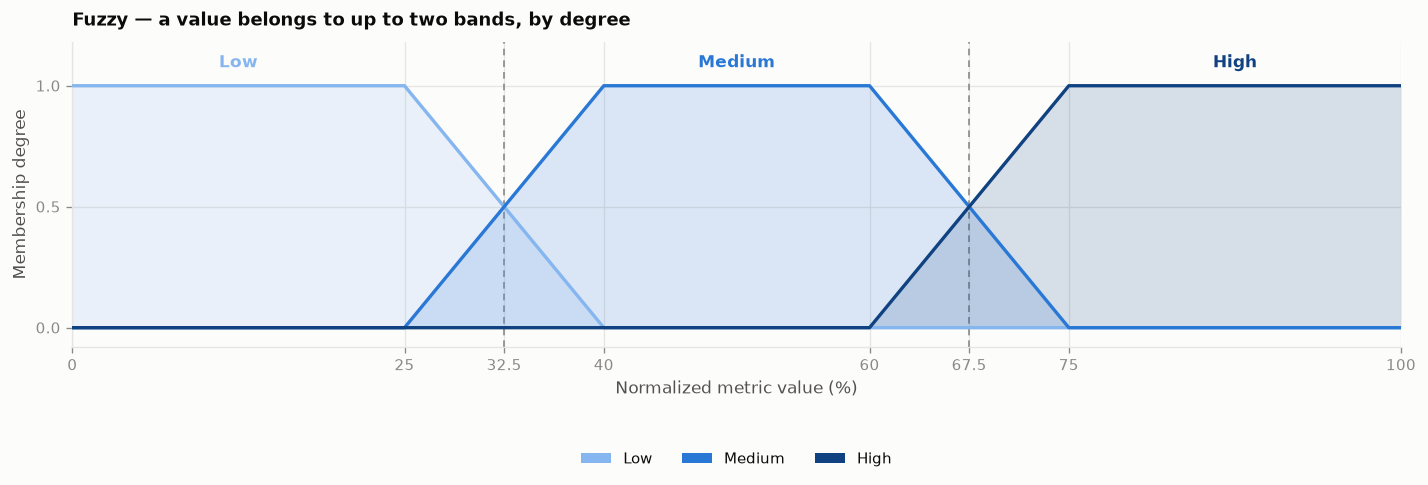

In [ ]:
fig, ax_f = plt.subplots(figsize=(12, 4.4))

for label in LABELS:
    ax_f.fill_between(x, degrees[label], color=BAND_COLORS[label], alpha=0.16,
                      linewidth=0, zorder=2)
    ax_f.plot(x, degrees[label], color=BAND_COLORS[label], linewidth=2, zorder=3)

annotate_cuts(ax_f)
ax_f.set_ylim(-0.08, 1.18)
ax_f.set_yticks([0, 0.5, 1.0])
ax_f.set_ylabel('Membership degree')
ax_f.set_title('Fuzzy — a value belongs to up to two bands, by degree')
for label, (_, b, c, _) in TRAPEZOIDS.items():
    ax_f.annotate(BAND_TITLE[label], xy=((b + c) / 2, 1.06), ha='center', va='bottom',
                color=BAND_COLORS[label], fontsize=10, fontweight='semibold')

partition_xaxis(ax_f)
band_legend(ax_f, loc='upper center', bbox_to_anchor=(0.5, -0.3), ncols=3)

plt.tight_layout()
plt.show()

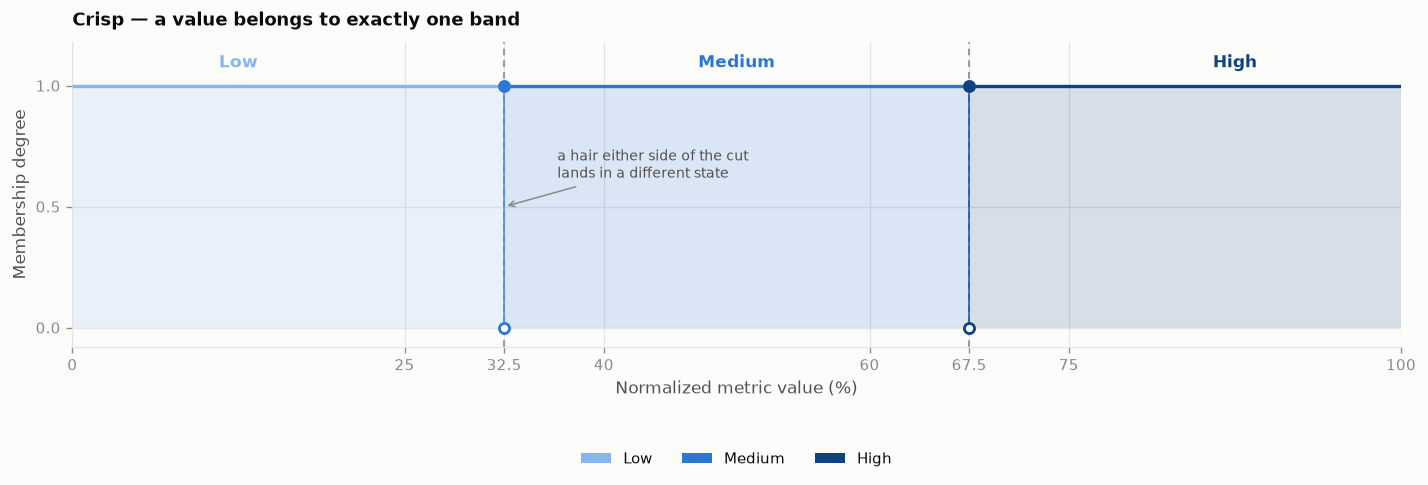

,rule,width of the range
crisp band,,
Low,0 <= value < 32.5,32.5%
Medium,32.5 <= value < 67.5,35%
High,value >= 67.5,32.5%


In [ ]:
def endpoint(ax, xv, yv, color, closed):
    """Filled dot where the indicator takes the value, hollow where it does not."""
    ax.plot([xv], [yv], marker='o', markersize=6, zorder=5,
            markerfacecolor=color if closed else SURFACE,
            markeredgecolor=color, markeredgewidth=1.6)


# The crisp bands are read back out of Crisp.label, not re-derived here.
edges = [0.0, LOW_CUT, HIGH_CUT, 100.0]
crisp_bands = [
    (lo, hi, crisp.label((lo + hi) / 2))
    for lo, hi in zip(edges[:-1], edges[1:])
]

fig, ax_c = plt.subplots(figsize=(12, 4.4))

for lo, hi, label in crisp_bands:
    color = BAND_COLORS[label]
    xs = np.linspace(lo, hi, 100)
    ax_c.fill_between(xs, 1, color=color, alpha=0.16, linewidth=0, zorder=2)
    ax_c.plot([lo, hi], [1, 1], color=color, linewidth=2, zorder=3, solid_capstyle='butt')
    if lo > 0:  # the band switches on here
        ax_c.plot([lo, lo], [0, 1], color=color, linewidth=1.2, alpha=0.5, zorder=3)
        endpoint(ax_c, lo, 1, color, closed=True)
        endpoint(ax_c, lo, 0, color, closed=False)
    if hi < 100:  # and off here
        ax_c.plot([hi, hi], [0, 1], color=color, linewidth=1.2, alpha=0.5, zorder=3)
        endpoint(ax_c, hi, 1, color, closed=False)
        endpoint(ax_c, hi, 0, color, closed=True)

annotate_cuts(ax_c)
ax_c.set_ylim(-0.08, 1.18)
ax_c.set_yticks([0, 0.5, 1.0])
ax_c.set_ylabel('Membership degree')
ax_c.set_title('Crisp — a value belongs to exactly one band')
for label, (_, b, c, _) in TRAPEZOIDS.items():
    ax_c.annotate(BAND_TITLE[label], xy=((b + c) / 2, 1.06), ha='center', va='bottom',
                color=BAND_COLORS[label], fontsize=10, fontweight='semibold')

ax_c.annotate('a hair either side of the cut\nlands in a different state',
              xy=(LOW_CUT, 0.5), xytext=(LOW_CUT + 4, 0.62), fontsize=8.5, color=INK_2,
              arrowprops=dict(arrowstyle='->', color=INK_MUTED, linewidth=0.9))

partition_xaxis(ax_c)
band_legend(ax_c, loc='upper center', bbox_to_anchor=(0.5, -0.3), ncols=3)

plt.tight_layout()
plt.show()

pd.DataFrame(
    [{'crisp band': BAND_TITLE[label],
      'rule': f'{lo:g} <= value < {hi:g}' if hi < 100 else f'value >= {lo:g}',
      'width of the range': f'{hi - lo:g}%'}
     for lo, hi, label in crisp_bands]
).set_index('crisp band')

## 4. What the hard cut costs

Two observations 0.2 percentage points apart, either side of the 32.5% cut,
with the other three metrics held on their `medium` plateau. Under the crisp
map the whole TD update changes address: the two observations land in different
Q-table entries and share nothing. Under the fuzzy map they activate the *same*
two states and merely shift a little weight between them.

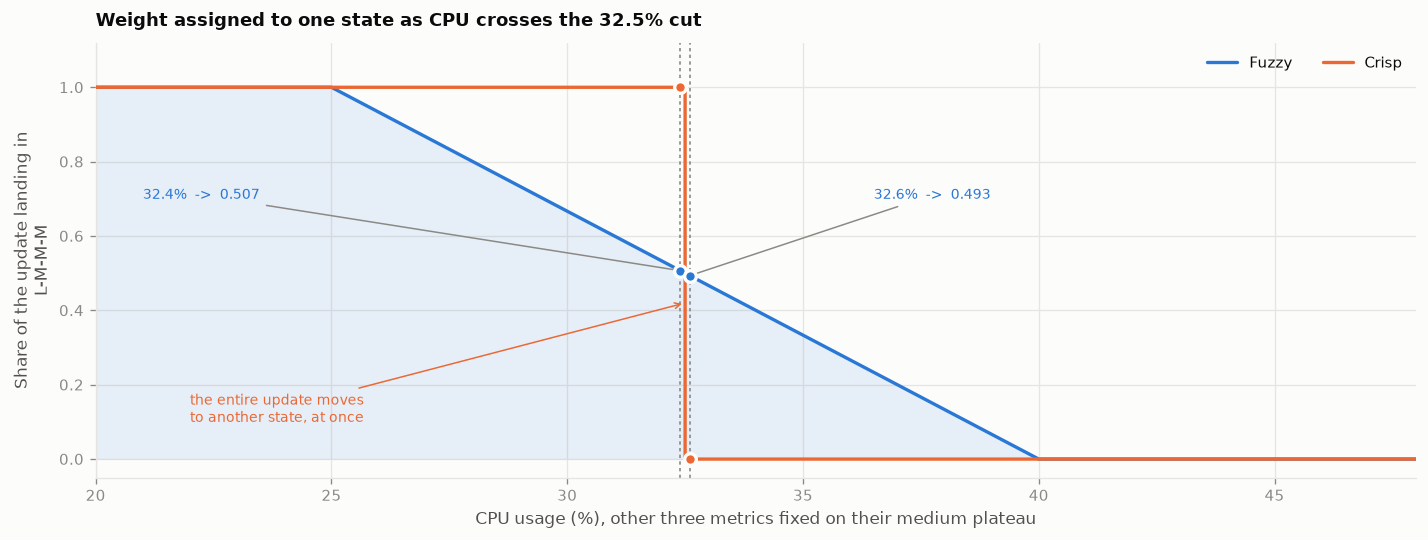

Fuzzy: both observations activate the same 2 states; 1.3% of the update weight moves between them.
Crisp: 2 distinct states, sharing nothing; 100.0% of the update moves.


,crisp state,fuzzy states,w[L-M-M-M],w[M-M-M-M]
cpu_usage,,,,
32.4%,L-M-M-M,2,0.5067,0.4933
32.6%,M-M-M-M,2,0.4933,0.5067


In [ ]:
TARGET = ('low', 'medium', 'medium', 'medium')

# The other three metrics sit on their medium plateau (memory and response time
# at 50%, 5 replicas -> 44.4%), so cpu_usage is the only metric that moves.
BASE_OBS = {'memory_usage': 50.0, 'response_time': 50.0, 'last_replica': 5}


def obs_at(cpu):
    return {'cpu_usage': float(cpu), **BASE_OBS}


def target_weight(cpu):
    """Share of the update that lands in TARGET, under each representation."""
    obs = obs_at(cpu)
    fuzzy_w = dict(fuzzy.get_activations(obs)).get(TARGET, 0.0)
    crisp_w = 1.0 if crisp.get_state_key(obs) == TARGET else 0.0
    return fuzzy_w, crisp_w


sweep = np.linspace(20, 48, 561)
fuzzy_w, crisp_w = (np.array(v) for v in zip(*(target_weight(v) for v in sweep)))

probes = [LOW_CUT - 0.1, LOW_CUT + 0.1]

fig, ax = plt.subplots(figsize=(12, 4.6))

ax.plot(sweep, fuzzy_w, color=REPR_COLORS['Fuzzy'], linewidth=2, label='Fuzzy', zorder=3)
ax.plot(sweep, crisp_w, color=REPR_COLORS['Crisp'], linewidth=2, label='Crisp', zorder=3,
        drawstyle='steps-post')
ax.fill_between(sweep, fuzzy_w, color=REPR_COLORS['Fuzzy'], alpha=0.1, linewidth=0)

for probe in probes:
    ax.axvline(probe, color=INK_MUTED, linewidth=1, linestyle=(0, (2, 2)), zorder=1)
    fw, cw = target_weight(probe)
    for value, key in ((fw, 'Fuzzy'), (cw, 'Crisp')):
        ax.plot([probe], [value], marker='o', markersize=7, markerfacecolor=REPR_COLORS[key],
                markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)

ax.annotate(f'{probes[0]:g}%  ->  {target_weight(probes[0])[0]:.3f}',
            xy=(probes[0], target_weight(probes[0])[0]), xytext=(21.0, 0.70),
            fontsize=8.5, color=REPR_COLORS['Fuzzy'],
            arrowprops=dict(arrowstyle='-', color=INK_MUTED, linewidth=0.9))
ax.annotate(f'{probes[1]:g}%  ->  {target_weight(probes[1])[0]:.3f}',
            xy=(probes[1], target_weight(probes[1])[0]), xytext=(36.5, 0.70),
            fontsize=8.5, color=REPR_COLORS['Fuzzy'],
            arrowprops=dict(arrowstyle='-', color=INK_MUTED, linewidth=0.9))
ax.annotate('the entire update moves\nto another state, at once',
            xy=(LOW_CUT, 0.42), xytext=(22.0, 0.10), fontsize=8.5,
            color=REPR_COLORS['Crisp'],
            arrowprops=dict(arrowstyle='->', color=REPR_COLORS['Crisp'], linewidth=0.9))

ax.set_xlim(20, 48)
ax.set_ylim(-0.05, 1.12)
ax.set_xlabel('CPU usage (%), other three metrics fixed on their medium plateau')
ax.set_ylabel(f'Share of the update landing in\n{state_label(TARGET)}')
ax.set_title('Weight assigned to one state as CPU crosses the 32.5% cut')
ax.legend(loc='upper right', ncols=2)

plt.tight_layout()
plt.show()

rows = []
for probe in probes:
    obs = obs_at(probe)
    activations = dict(fuzzy.get_activations(obs))
    rows.append({
        'cpu_usage': f'{probe:g}%',
        'crisp state': state_label(crisp.get_state_key(obs)),
        'fuzzy states': len(activations),
        f'w[{state_label(TARGET)}]': round(activations.get(TARGET, 0.0), 4),
        'w[M-M-M-M]': round(activations.get(('medium',) * 4, 0.0), 4),
    })
probe_table = pd.DataFrame(rows).set_index('cpu_usage')

a, b = (dict(fuzzy.get_activations(obs_at(p))) for p in probes)
moved = sum(abs(a.get(k, 0.0) - b.get(k, 0.0)) for k in set(a) | set(b)) / 2
crisp_keys = {crisp.get_state_key(obs_at(p)) for p in probes}

print(f'Fuzzy: both observations activate the same {len(set(a) & set(b))} states; '
      f'{moved:.1%} of the update weight moves between them.')
print(f'Crisp: {len(crisp_keys)} distinct states, sharing nothing; '
      f'100.0% of the update moves.')
probe_table

## 5. One observation, sixteen states

When all four metrics sit in an overlap zone, each contributes two labels and
the product t-norm spreads one observation over 2<sup>4</sup> = 16 Q-table
entries. The crisp agent picks the single strongest of those — which, on a
Ruspini partition, is always the top bar — and puts the whole update there.

C:\Users\indra\AppData\Local\Temp\ipykernel_34304\2958835480.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
findfont: Failed to find font weight semibold, now using 700.


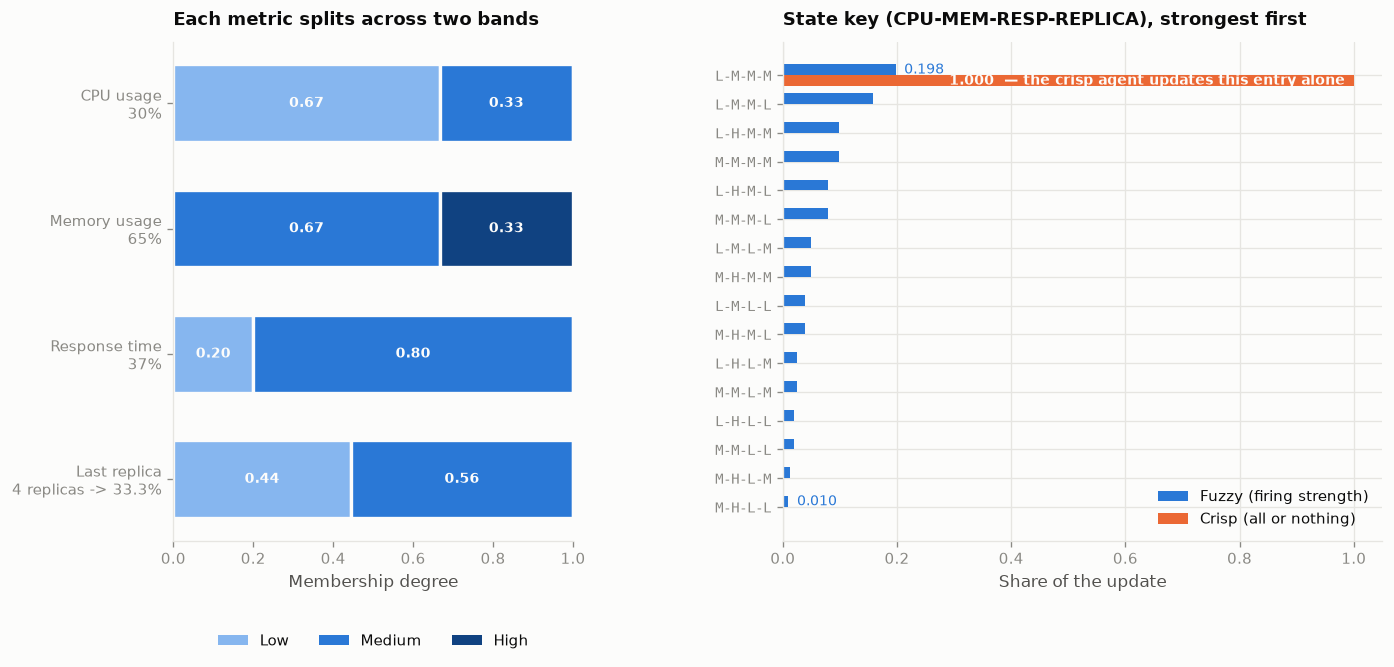

Active states     : 16
Weights sum to    : 1.000000
Crisp state       : L-M-M-M  (fuzzy weight 0.1975)
Strongest fuzzy   : L-M-M-M


,cpu_usage,memory_usage,response_time,last_replica,weight
state,,,,,
L-M-M-M,low,medium,medium,medium,0.19753
L-M-M-L,low,medium,medium,low,0.15802
L-H-M-M,low,high,medium,medium,0.09877
M-M-M-M,medium,medium,medium,medium,0.09877
L-H-M-L,low,high,medium,low,0.07901
M-M-M-L,medium,medium,medium,low,0.07901
L-M-L-M,low,medium,low,medium,0.04938
M-H-M-M,medium,high,medium,medium,0.04938
L-M-L-L,low,medium,low,low,0.03951


In [ ]:
# Every metric deliberately placed inside an overlap zone.
EXAMPLE_OBS = {
    'cpu_usage': 30.0,
    'memory_usage': 65.0,
    'response_time': 37.0,
    'last_replica': 4,
}

example_degrees = fuzzy.fuzzify(EXAMPLE_OBS)
activations = sorted(fuzzy.get_activations(EXAMPLE_OBS), key=lambda kv: kv[1], reverse=True)
crisp_key = crisp.get_state_key(EXAMPLE_OBS)

fig, (ax_m, ax_s) = plt.subplots(
    1, 2, figsize=(13, 5.4), gridspec_kw={'width_ratios': [1, 1.5], 'wspace': 0.42})

# --- left: what each metric contributes ---
ypos = np.arange(len(METRICS))[::-1]
left = np.zeros(len(METRICS))
for label in LABELS:
    widths = np.array([example_degrees[m][label] for m in METRICS])
    ax_m.barh(ypos, widths, left=left, height=0.62, color=BAND_COLORS[label],
              edgecolor=SURFACE, linewidth=2)
    for yv, w, l in zip(ypos, widths, left):
        if w > 0.12:
            ax_m.annotate(f'{w:.2f}', xy=(l + w / 2, yv), ha='center', va='center',
                          color=SURFACE, fontsize=8.5, fontweight='semibold')
    left += widths

metric_ticks = []
for m in METRICS:
    raw = EXAMPLE_OBS[m]
    if m == 'last_replica':
        shown = f'{raw:g} replicas -> {normalize_observation(m, raw, MAX_REPLICAS):.1f}%'
    else:
        shown = f'{raw:g}%'
    metric_ticks.append(f'{METRIC_TITLE[m]}\n{shown}')

ax_m.set_yticks(ypos)
ax_m.set_yticklabels(metric_ticks, fontsize=9)
ax_m.set_xlim(0, 1)
ax_m.set_xlabel('Membership degree')
ax_m.set_title('Each metric splits across two bands')
ax_m.grid(False)
band_legend(ax_m, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncols=3)

# --- right: the states that lights up ---
keys = [state_label(k) for k, _ in activations]
weights = np.array([w for _, w in activations])
crisp_weights = np.array([1.0 if k == crisp_key else 0.0 for k, _ in activations])
ypos = np.arange(len(keys))[::-1]
height = 0.38

ax_s.barh(ypos + height / 2, weights, height=height, color=REPR_COLORS['Fuzzy'],
          label='Fuzzy (firing strength)')
ax_s.barh(ypos - height / 2, crisp_weights, height=height, color=REPR_COLORS['Crisp'],
          label='Crisp (all or nothing)')

crisp_row = next(i for i, (k, _) in enumerate(activations) if k == crisp_key)
ax_s.annotate(f'{weights[0]:.3f}', xy=(weights[0] + 0.015, ypos[0] + height / 2),
              va='center', fontsize=8.5, color=REPR_COLORS['Fuzzy'])
ax_s.annotate('1.000  — the crisp agent updates this entry alone',
              xy=(0.985, ypos[crisp_row] - height / 2), ha='right', va='center',
              fontsize=8.5, color=SURFACE, fontweight='semibold')
ax_s.annotate(f'{weights[-1]:.3f}', xy=(weights[-1] + 0.015, ypos[-1] + height / 2),
              va='center', fontsize=8.5, color=REPR_COLORS['Fuzzy'])

ax_s.set_yticks(ypos)
ax_s.set_yticklabels(keys, fontsize=8.5, fontfamily='monospace')
ax_s.set_xlim(0, 1.05)
ax_s.set_xlabel('Share of the update')
ax_s.set_title('State key (CPU-MEM-RESP-REPLICA), strongest first')
ax_s.legend(loc='lower right')

plt.tight_layout()
plt.show()

print(f'Active states     : {len(activations)}')
print(f'Weights sum to    : {sum(w for _, w in activations):.6f}')
print(f'Crisp state       : {state_label(crisp_key)}  (fuzzy weight {dict(activations)[crisp_key]:.4f})')
print(f'Strongest fuzzy   : {state_label(activations[0][0])}')

pd.DataFrame(
    [{'state': state_label(k), **{m: lab for m, lab in zip(METRICS, k)}, 'weight': round(w, 5)}
     for k, w in activations]
).set_index('state')

## 6. `last_replica`, the metric that is not already a percentage

CPU, memory and response time arrive as percentages. The replica count arrives
as an integer in `1..MAX_REPLICAS` and is rescaled onto the same 0-100 axis, so
the partition means something different for it: with `MAX_REPLICAS = 10`, one
replica step is 11.1 percentage points, and only two of the ten counts land in
an overlap zone.

C:\Users\indra\AppData\Local\Temp\ipykernel_34304\1147701093.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
findfont: Failed to find font weight semibold, now using 700.


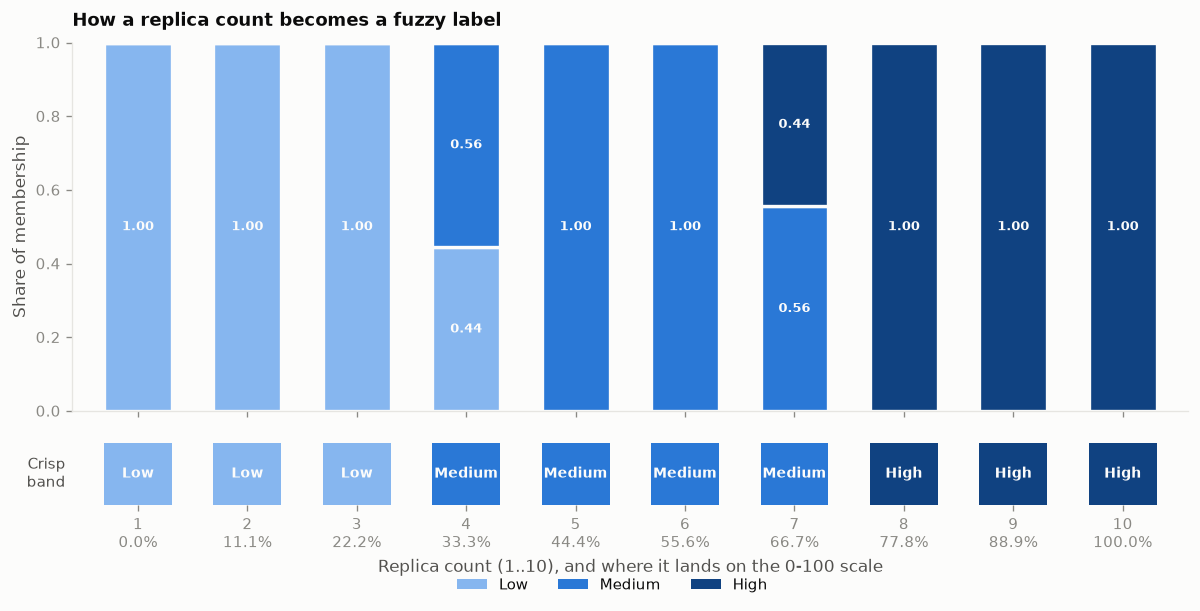

,normalized (%),Low,Medium,High,crisp band,active labels
replicas,,,,,,
1,0.0,1.000,0.000,0.000,Low,1
2,11.1,1.000,0.000,0.000,Low,1
3,22.2,1.000,0.000,0.000,Low,1
4,33.3,0.444,0.556,0.000,Medium,2
5,44.4,0.000,1.000,0.000,Medium,1
6,55.6,0.000,1.000,0.000,Medium,1
7,66.7,0.000,0.556,0.444,Medium,2
8,77.8,0.000,0.000,1.000,High,1
9,88.9,0.000,0.000,1.000,High,1


In [ ]:
replicas = np.arange(1, MAX_REPLICAS + 1)
normalized = np.array([normalize_observation('last_replica', float(r), MAX_REPLICAS)
                       for r in replicas])
replica_degrees = {
    label: np.array([fuzzy.fuzzify({'last_replica': float(r)})['last_replica'][label]
                     for r in replicas])
    for label in LABELS
}
replica_crisp = [crisp.label(v) for v in normalized]

fig, (ax, ax_band) = plt.subplots(
    2, 1, figsize=(12, 5), sharex=True,
    gridspec_kw={'height_ratios': [6, 1], 'hspace': 0.15})

bottom = np.zeros(len(replicas))
for label in LABELS:
    values = replica_degrees[label]
    ax.bar(replicas, values, bottom=bottom, width=0.62, color=BAND_COLORS[label],
           edgecolor=SURFACE, linewidth=2)
    for r, v, b in zip(replicas, values, bottom):
        if v > 0.15:
            ax.annotate(f'{v:.2f}', xy=(r, b + v / 2), ha='center', va='center',
                        color=SURFACE, fontsize=8, fontweight='semibold')
    bottom += values

ax.set_ylim(0, 1)
ax.set_ylabel('Share of membership')
ax.set_title('How a replica count becomes a fuzzy label')
ax.grid(False)

# The crisp assignment as its own lane, so it reads as a second answer to the
# same question rather than as a caption on the bars.
for r, label in zip(replicas, replica_crisp):
    ax_band.bar(r, 1, width=0.62, color=BAND_COLORS[label])
    ax_band.annotate(BAND_TITLE[label], xy=(r, 0.5), ha='center', va='center',
                     color=SURFACE, fontsize=8.5, fontweight='semibold')

ax_band.set_xticks(replicas)
ax_band.set_xticklabels([f'{r}\n{v:.1f}%' for r, v in zip(replicas, normalized)])
ax_band.set_xlim(0.4, MAX_REPLICAS + 0.6)
ax_band.set_ylim(0, 1)
ax_band.set_yticks([])
ax_band.set_ylabel('Crisp\nband', rotation=0, ha='right', va='center', fontsize=9)
ax_band.set_xlabel(f'Replica count (1..{MAX_REPLICAS}), '
                   f'and where it lands on the 0-100 scale')
ax_band.grid(False)
for spine in ax_band.spines.values():
    spine.set_visible(False)
band_legend(fig, loc='lower center', bbox_to_anchor=(0.5, -0.06), ncols=3)

plt.tight_layout()
plt.show()

replica_table = pd.DataFrame({
    'replicas': replicas,
    'normalized (%)': normalized.round(1),
    **{BAND_TITLE[label]: replica_degrees[label].round(3) for label in LABELS},
    'crisp band': [BAND_TITLE[label] for label in replica_crisp],
    'active labels': [int(sum(replica_degrees[label][i] > 0 for label in LABELS))
                      for i in range(len(replicas))],
}).set_index('replicas')
replica_table

## 7. The partition against the run it actually saw

Everything above is geometry. This section replays the observations of the
60-episode training run through the same `Fuzzy` and `Crisp` objects the agent
used, to ask where the workload actually put the four metrics — the partition
only earns its keep where the data lands.

The fuzzy agent's own run is used throughout: each agent drives its own replica
trajectory, so pooling the three would blur the distributions rather than
sharpen them.

One thing to know about the CSV before reading anything off it: **a row mixes
two moments.** The metric columns come from `info`, the state the step ended
in, while `active_states` counts the observation the action was chosen from —
the previous row's metrics. Section 8 shows the two lining up exactly once that
one-row offset is applied.

In [ ]:
TRAIN_DIR = Path('data/training/60-episodes')
RUN_PATTERN = 'train_qlearningfuzzy_*.csv'

matches = sorted(TRAIN_DIR.glob(RUN_PATTERN))
if not matches:
    raise FileNotFoundError(f'No file matching {RUN_PATTERN} in {TRAIN_DIR}')
run = pd.read_csv(matches[0])

# The column each metric arrives in. `response_time` is already the value the
# agent observed: a percentage of the response-time SLO, capped at 100 (the
# uncapped figure is logged separately as response_time_percentage).
SOURCE_COLUMN = {
    'cpu_usage': 'cpu_usage',
    'memory_usage': 'memory_usage',
    'response_time': 'response_time',
    'last_replica': 'replica_state',
}

norm = pd.DataFrame({
    metric: [normalize_observation(metric, float(v), MAX_REPLICAS) for v in run[column]]
    for metric, column in SOURCE_COLUMN.items()
})
observations = [
    {metric: float(run[column].iloc[i]) for metric, column in SOURCE_COLUMN.items()}
    for i in range(len(run))
]

over_slo = float((run['response_time_percentage'] > 100).mean())
print(f'Run       : {matches[0].name}')
print(f'Steps     : {len(run)} over {run["episode"].nunique()} episodes')
print(f'Latency   : {over_slo:.1%} of steps ran past the response-time SLO and reach the '
      f'fuzzifier pinned at 100%, deep inside `high`')
norm.describe().round(1)

Run       : train_qlearningfuzzy_1784557464_.csv
Steps     : 1800 over 60 episodes
Latency   : 36.4% of steps ran past the response-time SLO and reach the fuzzifier pinned at 100%, deep inside `high`


,cpu_usage,memory_usage,response_time,last_replica
count,1800.0,1800.0,1800.0,1800.0
mean,46.4,3.0,48.5,48.4
std,23.9,2.5,42.3,33.7
min,0.0,0.0,0.0,0.0
25%,27.9,1.9,11.1,22.2
50%,46.1,2.2,23.8,44.4
75%,58.0,3.1,100.0,88.9
max,99.8,35.5,100.0,100.0


C:\Users\indra\AppData\Local\Temp\ipykernel_34304\707227781.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
findfont: Failed to find font weight semibold, now using 700.


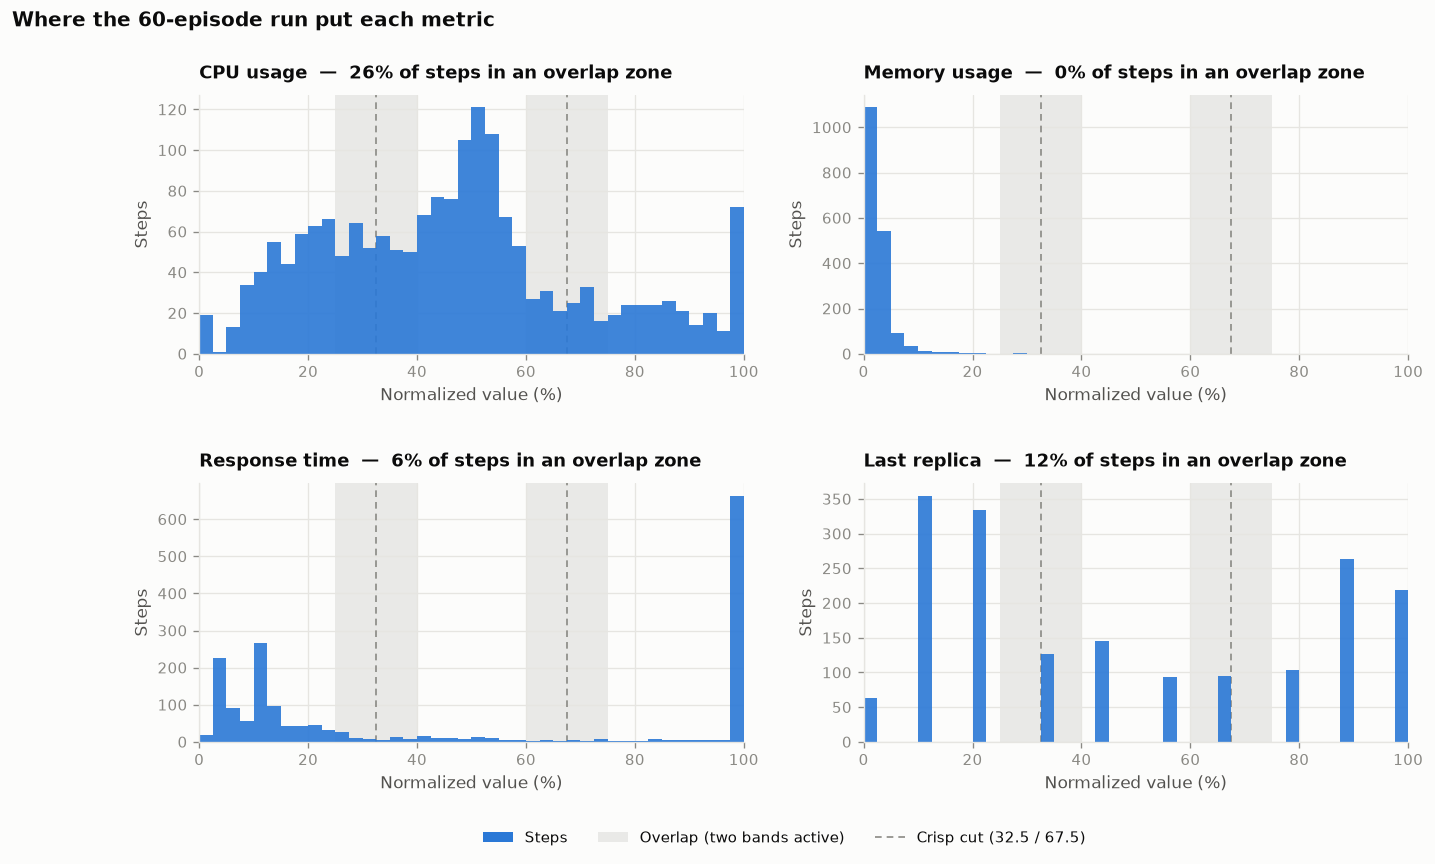

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), gridspec_kw={'hspace': 0.5, 'wspace': 0.22})
bins = np.linspace(0, 100, 41)
OVERLAP_WASH = 0.16

for ax, metric in zip(axes.flat, METRICS):
    values = norm[metric].to_numpy()

    # The partition sits behind the data as the cut lines and the overlap
    # zones, so the panel keeps a single y-axis (counts) rather than borrowing
    # a second one for membership degrees. Band membership is not shaded in as
    # well: four washes of the same hue would blur into each other, and the
    # next figure gives the band composition properly.
    for lo, hi in OVERLAPS:
        ax.axvspan(lo, hi, color=INK_MUTED, alpha=OVERLAP_WASH, linewidth=0, zorder=0)

    ax.hist(values, bins=bins, color=REPR_COLORS['Fuzzy'], alpha=0.9, zorder=2)
    annotate_cuts(ax)

    in_overlap = np.mean([any(lo <= v <= hi for lo, hi in OVERLAPS) for v in values])
    ax.set_title(f'{METRIC_TITLE[metric]}  —  {in_overlap:.0%} of steps in an overlap zone')
    ax.set_xlim(0, 100)
    ax.set_xlabel('Normalized value (%)')
    ax.set_ylabel('Steps')

handles = [
    Patch(facecolor=REPR_COLORS['Fuzzy'], label='Steps'),
    Patch(facecolor=INK_MUTED, alpha=OVERLAP_WASH, label='Overlap (two bands active)'),
    Line2D([], [], color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1,
           label=f'Crisp cut ({LOW_CUT:g} / {HIGH_CUT:g})'),
]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.03), ncols=3)
fig.suptitle('Where the 60-episode run put each metric', x=0.005, ha='left',
             fontsize=12, fontweight='semibold')

plt.tight_layout()
plt.show()

C:\Users\indra\AppData\Local\Temp\ipykernel_34304\171818415.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


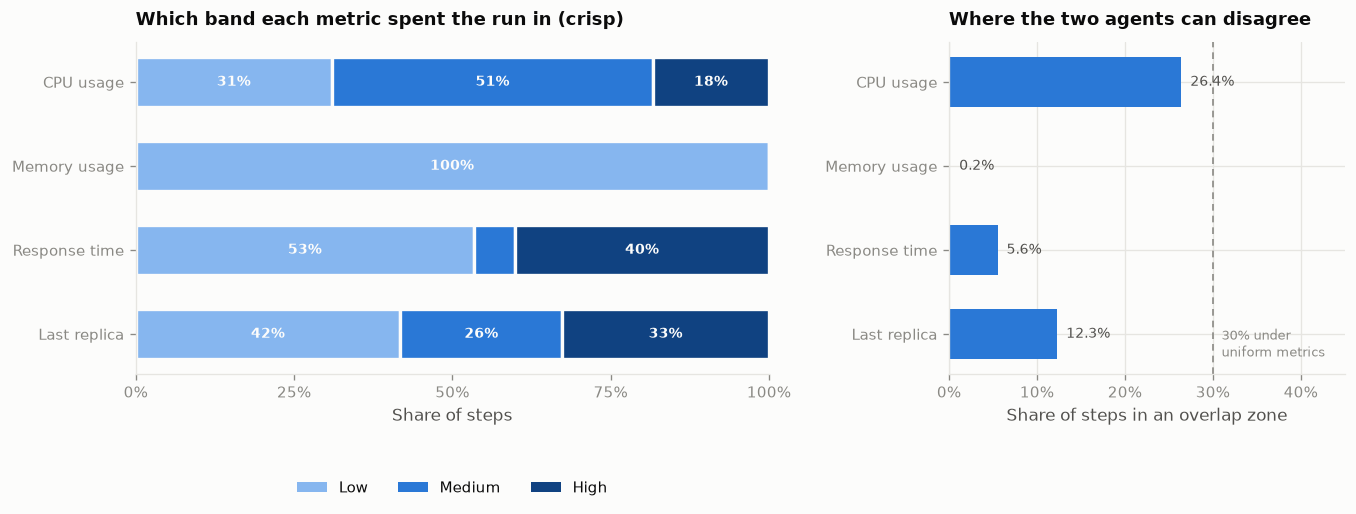

,Low,Medium,High,in overlap (%)
metric,,,,
CPU usage,31.0,50.7,18.3,26.4
Memory usage,99.9,0.1,0.0,0.2
Response time,53.4,6.5,40.1,5.6
Last replica,41.8,25.6,32.6,12.3


In [ ]:
fig, (ax_share, ax_overlap) = plt.subplots(
    1, 2, figsize=(13, 3.6), gridspec_kw={'width_ratios': [1.6, 1], 'wspace': 0.35})

ypos = np.arange(len(METRICS))[::-1]
band_share = {
    label: np.array([
        float(np.mean([crisp.label(v) == label for v in norm[metric]])) for metric in METRICS
    ])
    for label in LABELS
}

left = np.zeros(len(METRICS))
for label in LABELS:
    widths = band_share[label]
    ax_share.barh(ypos, widths, left=left, height=0.6, color=BAND_COLORS[label],
                  edgecolor=SURFACE, linewidth=2)
    for yv, w, l in zip(ypos, widths, left):
        if w > 0.08:
            ax_share.annotate(f'{w:.0%}', xy=(l + w / 2, yv), ha='center', va='center',
                              color=SURFACE, fontsize=8.5, fontweight='semibold')
    left += widths

ax_share.set_yticks(ypos)
ax_share.set_yticklabels([METRIC_TITLE[m] for m in METRICS])
ax_share.set_xlim(0, 1)
ax_share.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax_share.set_xticklabels(['0%', '25%', '50%', '75%', '100%'])
ax_share.set_xlabel('Share of steps')
ax_share.set_title('Which band each metric spent the run in (crisp)')
ax_share.grid(False)
band_legend(ax_share, loc='upper center', bbox_to_anchor=(0.5, -0.28), ncols=3)

overlap_share = np.array([
    float(np.mean([any(lo <= v <= hi for lo, hi in OVERLAPS) for v in norm[metric]]))
    for metric in METRICS
])
ax_overlap.barh(ypos, overlap_share, height=0.6, color=REPR_COLORS['Fuzzy'])
for yv, w in zip(ypos, overlap_share):
    ax_overlap.annotate(f'{w:.1%}', xy=(w + 0.01, yv), va='center', fontsize=8.5,
                        color=INK_2)
ax_overlap.axvline(OVERLAP_WIDTH / 100, color=INK_MUTED, linestyle=(0, (4, 3)), linewidth=1)
ax_overlap.annotate(f'{OVERLAP_WIDTH:g}% under\nuniform metrics',
                    xy=(OVERLAP_WIDTH / 100 + 0.01, 0.04), xycoords=('data', 'axes fraction'),
                    ha='left', va='bottom', fontsize=8, color=INK_MUTED)
ax_overlap.set_yticks(ypos)
ax_overlap.set_yticklabels([METRIC_TITLE[m] for m in METRICS])
ax_overlap.set_xlim(0, max(0.45, overlap_share.max() * 1.35))
ax_overlap.set_xticks([0, 0.1, 0.2, 0.3, 0.4])
ax_overlap.set_xticklabels(['0%', '10%', '20%', '30%', '40%'])
ax_overlap.set_xlabel('Share of steps in an overlap zone')
ax_overlap.set_title('Where the two agents can disagree')

plt.tight_layout()
plt.show()

pd.DataFrame({
    'metric': [METRIC_TITLE[m] for m in METRICS],
    **{BAND_TITLE[label]: (band_share[label] * 100).round(1) for label in LABELS},
    'in overlap (%)': (overlap_share * 100).round(1),
}).set_index('metric')

## 8. How many states one observation touches

A metric in an overlap zone doubles the number of active states, so the count
is 2<sup>k</sup> for `k` metrics in overlap. Under metrics spread uniformly over
0-100 that would be a binomial in `k` with p = the overlap width. The run is not
uniform — memory usage never left the bottom of its scale — so the observed
distribution sits well to the left of the theoretical one, and the fuzzy agent
paid much less for its softness than the geometry alone suggests.

Recomputed counts reproduce the logged active_states column for 100.0% of the 1740 steps that have a predecessor in the same episode


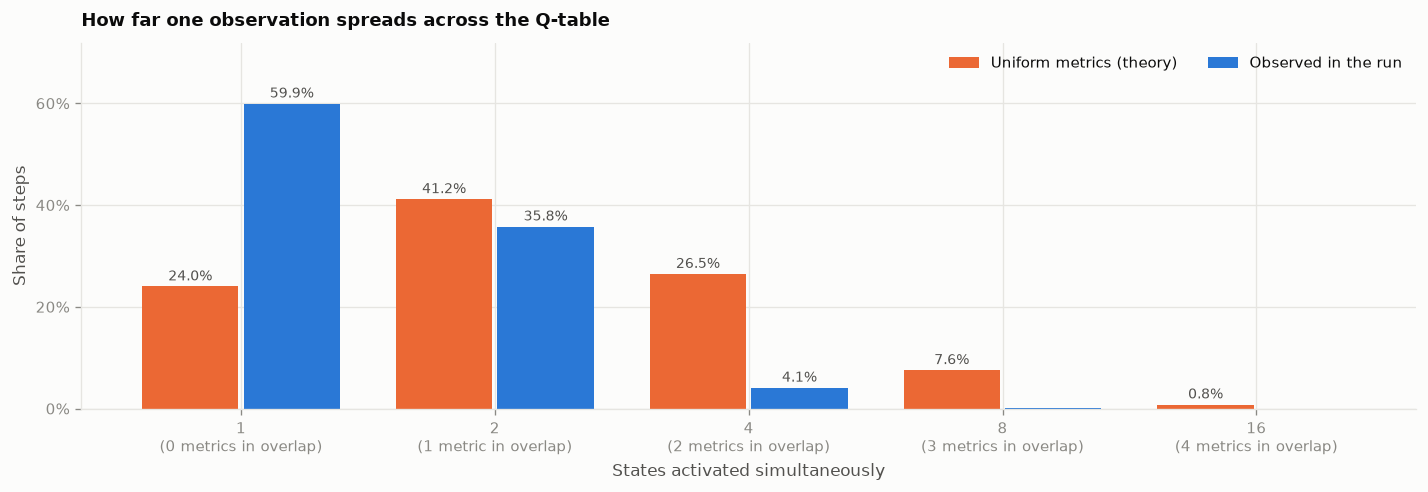

Mean active states per step  : 1.49 (theory under uniform metrics: 2.86)
Steps activating one state   : 59.9% (these are the steps where fuzzy and crisp agree exactly)


,metrics in overlap,theory (%),observed (%),steps
states activated,,,,
1,0,24.0,59.9,1079
2,1,41.2,35.8,644
4,2,26.5,4.1,74
8,3,7.6,0.2,3
16,4,0.8,0.0,0


In [ ]:
active_counts = np.array([len(fuzzy.get_activations(obs)) for obs in observations])

# Cross-check against what the agent logged at training time. A CSV row mixes
# two moments: the metric columns describe the state the step *ended* in, while
# `active_states` counts the activations of the observation the action was
# chosen *from* -- the previous row's metrics (trainer._write_csv_row is handed
# `obs` and `info` together). Recomputing with that one-row offset reproduces
# the logged column exactly, which is the end-to-end check that this notebook
# fuzzifies exactly what the agent fuzzified.
if 'active_states' in run.columns:
    has_predecessor = run['episode'] == run['episode'].shift(1)
    recomputed = pd.Series(active_counts).shift(1)
    agreement = float(
        (recomputed[has_predecessor] == run['active_states'][has_predecessor]).mean()
    )
    print(f'Recomputed counts reproduce the logged active_states column for '
          f'{agreement:.1%} of the {int(has_predecessor.sum())} steps that have a '
          f'predecessor in the same episode')

p_overlap = OVERLAP_WIDTH / 100
buckets = [2 ** k for k in range(len(METRICS) + 1)]
theory = np.array([comb(len(METRICS), k) * p_overlap ** k * (1 - p_overlap) ** (len(METRICS) - k)
                   for k in range(len(METRICS) + 1)])
observed = np.array([float(np.mean(active_counts == n)) for n in buckets])

fig, ax = plt.subplots(figsize=(12, 4.2))
xpos = np.arange(len(buckets))
width = 0.38

# The pair is offset by slightly more than half a bar so a hairline of surface
# separates the two rather than a border.
for offset, values, name in ((-width / 2 - 0.01, theory, 'Uniform metrics (theory)'),
                             (width / 2 + 0.01, observed, 'Observed in the run')):
    color = REPR_COLORS['Crisp'] if name.startswith('Uniform') else REPR_COLORS['Fuzzy']
    ax.bar(xpos + offset, values, width, color=color, label=name)
    for xv, v in zip(xpos + offset, values):
        if v > 0.004:
            ax.annotate(f'{v:.1%}', xy=(xv, v + 0.012), ha='center', fontsize=8.5, color=INK_2)

ax.set_xticks(xpos)
ax.set_xticklabels([f'{n}\n({k} metric{"s" if k != 1 else ""} in overlap)'
                    for k, n in enumerate(buckets)])
ax.set_ylim(0, max(theory.max(), observed.max()) * 1.2)
ax.set_yticks([0, 0.2, 0.4, 0.6])
ax.set_yticklabels(['0%', '20%', '40%', '60%'])
ax.set_xlabel('States activated simultaneously')
ax.set_ylabel('Share of steps')
ax.set_title('How far one observation spreads across the Q-table')
ax.legend(loc='upper right', ncols=2)

plt.tight_layout()
plt.show()

print(f'Mean active states per step  : {active_counts.mean():.2f} '
      f'(theory under uniform metrics: {sum(b * t for b, t in zip(buckets, theory)):.2f})')
print(f'Steps activating one state   : {np.mean(active_counts == 1):.1%} '
      f'(these are the steps where fuzzy and crisp agree exactly)')

pd.DataFrame({
    'states activated': buckets,
    'metrics in overlap': list(range(len(METRICS) + 1)),
    'theory (%)': (theory * 100).round(1),
    'observed (%)': (observed * 100).round(1),
    'steps': [int(np.sum(active_counts == n)) for n in buckets],
}).set_index('states activated')

## 9. What the two representations do with the same run

Both agents draw from the same pool of at most 3<sup>4</sup> = 81 keys. The
crisp agent hands each step to one of them; the fuzzy agent spreads the same
step over several, so it reaches keys the crisp agent never visits at all — on
a fraction of a step each, which is the point: a state the run only ever
brushed past still gets its share of the evidence. The bars are shares of the
run's total update mass: visits for the crisp agent, summed firing strength for
the fuzzy agent.

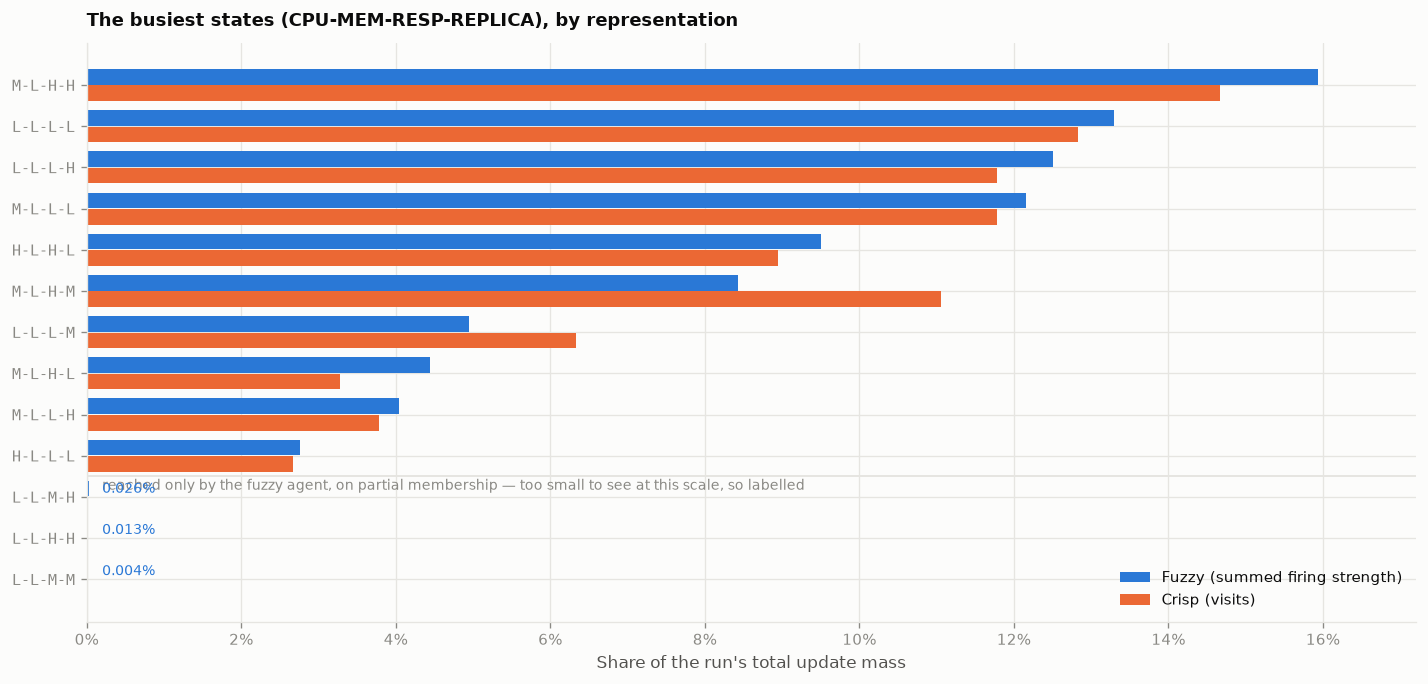

Distinct states visited, crisp :  21 of 81
Distinct states touched, fuzzy :  24 of 81 (3 of them never visited by the crisp agent)
Busiest single state, crisp    : 14.7% of the update mass
Busiest single state, fuzzy    : 15.9% of the update mass


,fuzzy mass (%),crisp visits (%),crisp visits
state,,,
M-L-H-H,15.93,14.67,264
L-L-L-L,13.30,12.83,231
L-L-L-H,12.50,11.78,212
M-L-L-L,12.16,11.78,212
H-L-H-L,9.50,8.94,161
M-L-H-M,8.43,11.06,199
L-L-L-M,4.95,6.33,114
M-L-H-L,4.44,3.28,59
M-L-L-H,4.04,3.78,68


In [ ]:
MAX_KEYS = len(LABELS) ** len(METRICS)

crisp_mass, fuzzy_mass = {}, {}
for obs in observations:
    crisp_mass[crisp.get_state_key(obs)] = crisp_mass.get(crisp.get_state_key(obs), 0.0) + 1.0
    for key, weight in fuzzy.get_activations(obs):
        fuzzy_mass[key] = fuzzy_mass.get(key, 0.0) + weight

crisp_share = {k: v / len(observations) for k, v in crisp_mass.items()}
fuzzy_share = {k: v / len(observations) for k, v in fuzzy_mass.items()}

only_fuzzy = set(fuzzy_share) - set(crisp_share)
busiest = sorted(set(fuzzy_share) - only_fuzzy, key=lambda k: fuzzy_share[k],
                 reverse=True)[:10]
# The states only the fuzzy agent reaches are far too small to make the top ten,
# and are exactly what this figure is about, so they are appended explicitly.
tail = sorted(only_fuzzy, key=lambda k: fuzzy_share[k], reverse=True)[:4]
top = busiest + tail

fig, ax = plt.subplots(figsize=(12, 5.8))
ypos = np.arange(len(top))[::-1]
height = 0.38

ax.barh(ypos + height / 2 + 0.01, [fuzzy_share.get(k, 0.0) for k in top], height,
        color=REPR_COLORS['Fuzzy'], label='Fuzzy (summed firing strength)')
ax.barh(ypos - height / 2 - 0.01, [crisp_share.get(k, 0.0) for k in top], height,
        color=REPR_COLORS['Crisp'], label='Crisp (visits)')

if tail:
    ax.axhline(ypos[len(busiest)] + 0.5, color=GRID, linewidth=1.2)
    ax.annotate('reached only by the fuzzy agent, on partial membership — '
                'too small to see at this scale, so labelled',
                xy=(0.002, ypos[len(busiest)] + 0.44), va='top', fontsize=8.5,
                color=INK_MUTED)
    for key, yv in zip(tail, ypos[len(busiest):]):
        ax.annotate(f'{fuzzy_share[key]:.3%}', xy=(0.002, yv + height / 2), va='center',
                    fontsize=8.5, color=REPR_COLORS['Fuzzy'])

ax.set_yticks(ypos)
ax.set_yticklabels([state_label(k) for k in top], fontsize=9, fontfamily='monospace')
ax.set_xlim(0, max(fuzzy_share.values()) * 1.08)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_xlabel('Share of the run\'s total update mass')
ax.set_title('The busiest states (CPU-MEM-RESP-REPLICA), by representation')
ax.legend(loc='lower right', ncols=1)

plt.tight_layout()
plt.show()

print(f'Distinct states visited, crisp : {len(crisp_share):>3} of {MAX_KEYS}')
print(f'Distinct states touched, fuzzy : {len(fuzzy_share):>3} of {MAX_KEYS} '
      f'({len(only_fuzzy)} of them never visited by the crisp agent)')
print(f'Busiest single state, crisp    : {max(crisp_share.values()):.1%} of the update mass')
print(f'Busiest single state, fuzzy    : {max(fuzzy_share.values()):.1%} of the update mass')

pd.DataFrame([
    {
        'state': state_label(k),
        'fuzzy mass (%)': round(fuzzy_share.get(k, 0.0) * 100, 2),
        'crisp visits (%)': round(crisp_share.get(k, 0.0) * 100, 2),
        'crisp visits': int(crisp_mass.get(k, 0)),
    }
    for k in top
]).set_index('state')

## Summary

- **One partition, four metrics.** Three trapezoids on a 0-100 scale, shared by
  CPU, memory, response time and the rescaled replica count. `low` and `medium`
  overlap on 25-40, `medium` and `high` on 60-75.
- **The partition is Ruspini**, so the degrees sum to 1 everywhere, the
  normalization in `get_activations` is a no-op, and the crisp cut-offs can be
  derived from the trapezoids rather than chosen: 32.5 and 67.5 are exactly
  where the memberships cross.
- **Crisp is fuzzy, rounded.** Same bands, same cuts, one label per metric.
  Its cost is at the cuts: two observations 0.2 pp apart land in different
  Q-table entries and share nothing, while the fuzzy agent moves ~1% of the
  update weight between the same two states.
- **Softness costs states.** With every metric in an overlap zone, one
  observation touches 16 entries. On the actual run the mean was far lower,
  because the workload kept memory usage pinned to the bottom of its scale.
- **Softness buys coverage, not dilution.** Over the same run the fuzzy agent
  touched more of the 81 available keys than the crisp agent visited, including
  a few the crisp agent never reached — while the busiest states carried much
  the same mass under both. Spreading the update did not thin it out where it
  mattered.

To re-run this against a different experiment, change `TRAIN_DIR` and
`RUN_PATTERN` in section 7; everything else follows from
`agent-dipa/rl/fuzzy.py`.